# 02 Frequentist inference: two errors and a line

*Teaching material. Not for clinical use.*

Six hundred and eighty patients were given blood products in one of two ratios. Within 24 hours, 12.7% died on one ratio and 17.0% on the other, a difference of 4.2 points. The paper reports no significant difference: P=.12 (E-72).

**Before reading on, guess.** Does the ratio matter?

- No: the trial found no difference
- Yes: four points is a great many lives
- The trial cannot tell either way
- Something else

Write the guess down. It is not marked, and the answer comes in the treatment section below.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline
from inference_labs.lenses import frequentist as freq
from inference_labs.lenses import rules

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # needs intervention, does not, published figure
PALE = "#6baed6"                                      # a second series: lighter, and drawn hollow or hatched
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)

# 100,000 synthetic casualties, seed 42, military cohort, every stream. Every result on them is a mechanism.
observed, truth = baseline.generator_sample()
need = truth["needs_lsi"].to_numpy(bool)
score = freq.fitted_score()
p = freq.probability(observed)

## The idea, before any medicine

A spam filter reads each email and gives it a score. Above a line, the email goes to the junk folder; below it, to the inbox. Set the line low and almost no junk gets through, but real letters vanish into junk. Set it high and every real letter arrives, along with a pile of junk. No setting removes both mistakes, because some real letters look like junk and some junk looks real.

**Plain.** Any test makes two kinds of mistake: it misses some of what it looks for, and it raises false alarms on some of what it should ignore. You cannot shrink one without growing the other. Where you set the line is a choice, not a fact. And a single study of a test, or of a treatment, is one sample: run it again on different people and the numbers move.

**Developer.** A test is a score and a threshold. Count four boxes, then two rates, and put an interval round each:

```python
hits   = sum(flag & need);   misses             = sum(~flag & need)
alarms = sum(flag & ~need);  correct_rejections = sum(~flag & ~need)
sensitivity = hits / (hits + misses)
specificity = correct_rejections / (correct_rejections + alarms)
```

The score here is a logistic regression on the four signs the MPTT-24 reads: walking, conscious level, respiratory rate and heart rate. It is fitted on 100,000 synthetic casualties and scored on a different 100,000. Its threshold is set where its specificity matches the MPTT-24's, so the two can be compared at the same rate of false alarms. A Wilson interval round each rate costs a few arithmetic operations.

**Technical.** Signal detection treats the score $S$ as drawn from one distribution when the condition is present and another when it is absent. A criterion $c$ gives

$$\mathrm{sens}(c) = P(S \ge c \mid D = 1), \qquad \mathrm{spec}(c) = P(S < c \mid D = 0),$$

and sweeping $c$ traces the receiver operating curve. The area under it is $P(S_1 > S_0)$, the chance that a random casualty in need scores above a random one not in need. A 95% confidence interval is a procedure that, over repeated samples, covers the true value 95% of the time; it is not a 95% probability about this one interval. A P value is the probability, if there were no effect, of a result at least as extreme as the one seen; a significance threshold is a line drawn on it in advance.

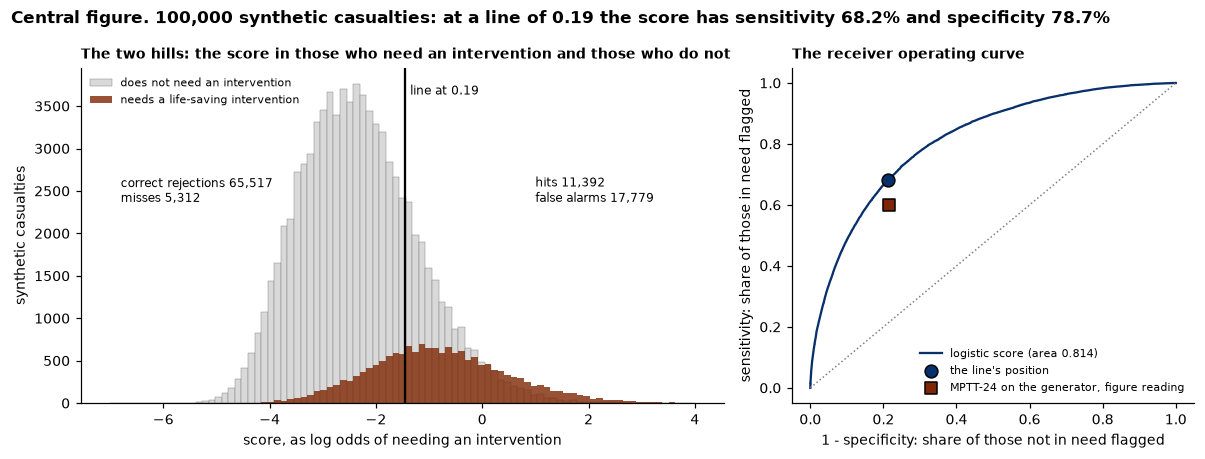

In [2]:
# Central figure: two hills and a sliding line. The control: change it and run the cell again.
THRESHOLD = score.threshold      # a probability between 0 and 1; the default is the score's operating threshold

flag = p >= THRESHOLD
a = freq.accuracy(flag, need)
logit = np.log(p / (1 - p))
cut = np.log(THRESHOLD / (1 - THRESHOLD))
bins = np.linspace(-7, 4, 90)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax.hist(logit[~need], bins=bins, color=LIGHT, edgecolor="grey", linewidth=0.3, label="does not need an intervention")
ax.hist(logit[need], bins=bins, color=DARK, alpha=0.8, label="needs a life-saving intervention")
ax.axvline(cut, color="black", linewidth=1.5)
ax.text(cut + 0.1, ax.get_ylim()[1] * 0.92, f"line at {THRESHOLD:.2f}", fontsize=8)
ymax = ax.get_ylim()[1]
ax.text(-6.8, ymax * 0.6, f"correct rejections {a['correct rejections']:,}\nmisses {a['misses']:,}", fontsize=8)
ax.text(1.0, ymax * 0.6, f"hits {a['hits']:,}\nfalse alarms {a['false alarms']:,}", fontsize=8)
ax.set_xlabel("score, as log odds of needing an intervention")
ax.set_ylabel("synthetic casualties")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title("The two hills: the score in those who need an intervention and those who do not", loc="left", fontsize=9)

r = freq.roc()
bx.plot(r["fpr"], r["tpr"], color=MID, linewidth=1.5, label=f"logistic score (area {r['auc']:.3f})")
bx.scatter(1 - a["specificity"][0], a["sensitivity"][0], s=70, color=MID, edgecolor="black", zorder=3,
           label="the line's position")
rule = r["points"]["MPTT-24, figure (as published)"]
bx.scatter(1 - rule["specificity"][0], rule["sensitivity"][0], s=70, marker="s", color=DARK, edgecolor="black",
           zorder=3, label="MPTT-24 on the generator, figure reading")
bx.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
bx.set_xlabel("1 - specificity: share of those not in need flagged")
bx.set_ylabel("sensitivity: share of those in need flagged")
bx.legend(fontsize=7, frameon=False, loc="lower right")
bx.set_title("The receiver operating curve", loc="left", fontsize=9)
fig.suptitle(f"Central figure. 100,000 synthetic casualties: at a line of {THRESHOLD:.2f} the score has sensitivity "
             f"{a['sensitivity'][0]:.1%} and specificity {a['specificity'][0]:.1%}", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

The figure counts synthetic casualties, and every result on them is a **mechanism**: the generator's signs are drawn from assumed distributions, so the hills are the generator's, not any real cohort's. Move `THRESHOLD` and run the cell again: the hits and false alarms move together.

The square is the MPTT-24, under the reading of its published figure, on the same casualties. It sits below the curve: at the same rate of false alarms the score finds more of those in need, because the rule cuts each sign at a threshold and the score keeps the whole value. Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).

## By hand: a hundred casualties into four pens

Take the first hundred synthetic casualties. For each one there are two facts: whether the generator says they need a life-saving intervention, and whether the MPTT-24, read as its figure was published, puts them in Priority 1. Every casualty lands in exactly one of four pens: a hit (in need, flagged), a miss (in need, not flagged), a false alarm (not in need, flagged) or a correct rejection.

Count the four pens by hand from the table below before running the next cell.

In [3]:
hundred = freq.hundred()
hundred.head(20)

,id,needs,MPTT-24 Priority 1
0,1,False,True
1,2,False,False
2,3,False,False
3,4,False,True
4,5,False,False
5,6,False,False
6,7,False,True
7,8,False,False
8,9,False,True
9,10,False,False


In [4]:
pens = {"hits": 0, "misses": 0, "false alarms": 0, "correct rejections": 0}
for _, row in hundred.iterrows():                       # the same count in plain Python
    if row["needs"] and row["MPTT-24 Priority 1"]:
        pens["hits"] += 1
    elif row["needs"]:
        pens["misses"] += 1
    elif row["MPTT-24 Priority 1"]:
        pens["false alarms"] += 1
    else:
        pens["correct rejections"] += 1
library = freq.accuracy(hundred["MPTT-24 Priority 1"], hundred["needs"])
assert all(pens[k] == library[k] for k in pens)          # the library agrees with the hand count
in_need = pens["hits"] + pens["misses"]
sieve = rules.PUBLISHED["Military Sieve, military"]
expected = freq.expected_counts(sieve.sensitivity, sieve.specificity, in_need)
pd.DataFrame({"MPTT-24 on these hundred (counted)": pens,
              "Military Sieve's published point on the same hundred (expected)": {k: round(v, 1) for k, v in expected.items()}})

,MPTT-24 on these hundred (counted),Military Sieve's published point on the same hundred (expected)
hits,9,9.1
misses,12,11.9
false alarms,15,5.0
correct rejections,64,74.0


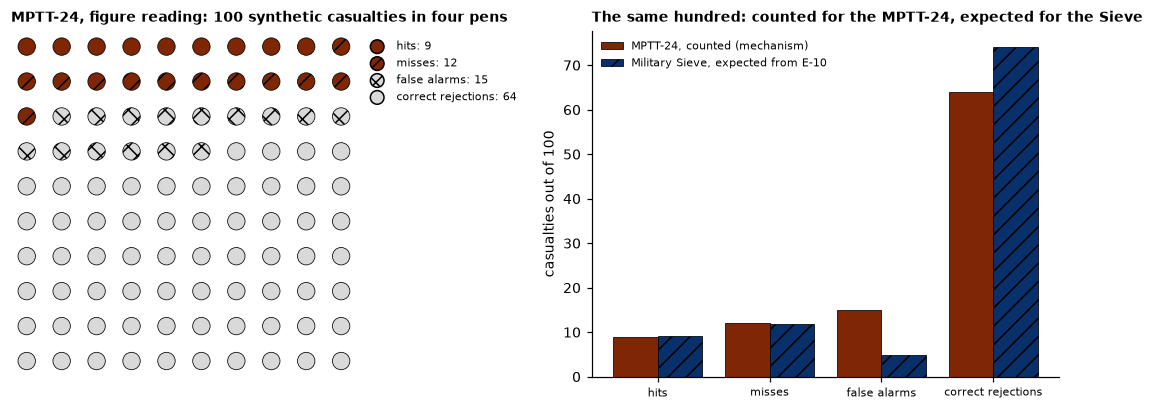

In [5]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
order = (("hits", DARK, ""), ("misses", DARK, "//"), ("false alarms", LIGHT, "xx"), ("correct rejections", LIGHT, ""))
k = 0
for name, colour, hatch in order:
    for _ in range(pens[name]):
        ax.scatter(k % 10, -(k // 10), s=130, color=colour, hatch=hatch, edgecolor="black", linewidth=0.5)
        k += 1
for name, colour, hatch in order:
    ax.scatter([], [], s=80, color=colour, hatch=hatch, edgecolor="black", label=f"{name}: {pens[name]}")
ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("MPTT-24, figure reading: 100 synthetic casualties in four pens", loc="left", fontsize=9)
names = [n for n, _, _ in order]
x = np.arange(len(names))
bx.bar(x - 0.2, [pens[n] for n in names], 0.4, color=DARK, edgecolor="black", linewidth=0.5,
       label="MPTT-24, counted (mechanism)")
bx.bar(x + 0.2, [expected[n] for n in names], 0.4, color=MID, edgecolor="black", linewidth=0.5, hatch="//",
       label="Military Sieve, expected from E-10")
bx.set_xticks(x, names, fontsize=7)
bx.set_ylabel("casualties out of 100")
bx.legend(fontsize=7, frameon=False)
bx.set_title("The same hundred: counted for the MPTT-24, expected for the Sieve", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

The Military Sieve is not coded here. The register holds its performance, not its algorithm (E-10), so its column is what its published operating point in the military registry, 43.2% sensitive and 93.7% specific, would do to a hundred with this many in need: expected counts, not casualties sorted. The MPTT-24 column is counted on the generator and is a mechanism.

Written as notation, with $\mathrm{TP}$, $\mathrm{FN}$, $\mathrm{FP}$ and $\mathrm{TN}$ the four pens,

$$\mathrm{sens} = \frac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}}, \qquad \mathrm{spec} = \frac{\mathrm{TN}}{\mathrm{TN} + \mathrm{FP}}.$$

## Diagnosis: one rule, many numbers

### First, the table

Before quoting any accuracy for the MPTT, produce the table. The MPTT and the MPTT-24 have been measured in several cohorts, and across the four combinations of cohort and tool behind E-13 sensitivity ran from 53.5% to 83.6% (E-13). The MPTT-24's figures were measured on first recorded hospital values, not pre-hospital ones (E-11), and the prospective MPTT cohort in an emergency department (E-07).

In [6]:
pd.DataFrame([{"rule": x.rule, "cohort": x.cohort, "sensitivity": x.sensitivity,
               "95% interval": f"{x.sensitivity_ci[0]:.3f} to {x.sensitivity_ci[1]:.3f}",
               "specificity": x.specificity, "95% interval ": f"{x.specificity_ci[0]:.3f} to {x.specificity_ci[1]:.3f}",
               "source": x.source} for x in freq.PUBLISHED])

,rule,cohort,sensitivity,95% interval,specificity,95% interval,source
0,MPTT,"military registry (JTTR), derivation",0.699,0.677 to 0.720,0.653,0.632 to 0.675,E-03
1,MPTT,civilian registry (TARN),0.576,0.569 to 0.582,0.715,0.712 to 0.718,E-05
2,MPTT,"Camp Bastion, prospective, 357 patients",0.836,0.780 to 0.883,0.510,0.426 to 0.595,E-07
3,MPTT-24,military registry (JTTR),0.667,0.645 to 0.689,0.699,0.678 to 0.719,E-09
4,MPTT-24,civilian registry (TARN),0.535,0.529 to 0.541,0.748,0.746 to 0.751,E-09


### The rule and the score on the generator, with intervals

The next table puts a 95% interval on every rate, by cohort and by where the scan is done, for the MPTT-24 under both readings of its voice step and for the score. The figure reading is the rule as published; the text reading is the one that matches the GCS on which E-09 was measured, labelled *as validated* (D-24). The setting changes only the scan, which none of these uses, so the two settings give the same figures. With 100,000 synthetic casualties a cohort, and over 56,000 in the injured view, the intervals are narrow; they say how precisely the generator's own value is known, not how well the rule works in any real cohort. Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).

The score was fitted on the military cohort. On the civilian cohort, whose physiology is assumed to move less with injury, it loses more specificity than the rule does: a learned weight carries the population it was learned on.

In [7]:
table = freq.accuracy_table()
table[table["scan"] == "scan before hospital"].drop(columns="scan")

,cohort,method,casualties,share in need,sensitivity,sensitivity 95% interval,specificity,specificity 95% interval
0,"military, every stream","MPTT-24, figure (as published)",100000,0.167,0.600,0.592 to 0.607,0.786,0.783 to 0.788
1,"military, every stream","MPTT-24, text (as validated)",100000,0.167,0.614,0.607 to 0.622,0.778,0.775 to 0.781
2,"military, every stream",logistic score,100000,0.167,0.682,0.675 to 0.689,0.787,0.784 to 0.789
6,"military, injured only","MPTT-24, figure (as published)",56634,0.265,0.627,0.619 to 0.634,0.737,0.733 to 0.741
7,"military, injured only","MPTT-24, text (as validated)",56634,0.265,0.641,0.634 to 0.649,0.731,0.726 to 0.735
8,"military, injured only",logistic score,56634,0.265,0.718,0.710 to 0.725,0.658,0.653 to 0.662
12,"civilian, injured civilians","MPTT-24, figure (as published)",100000,0.212,0.525,0.518 to 0.531,0.771,0.768 to 0.774
13,"civilian, injured civilians","MPTT-24, text (as validated)",100000,0.212,0.565,0.559 to 0.572,0.763,0.760 to 0.766
14,"civilian, injured civilians",logistic score,100000,0.212,0.532,0.525 to 0.539,0.709,0.706 to 0.712


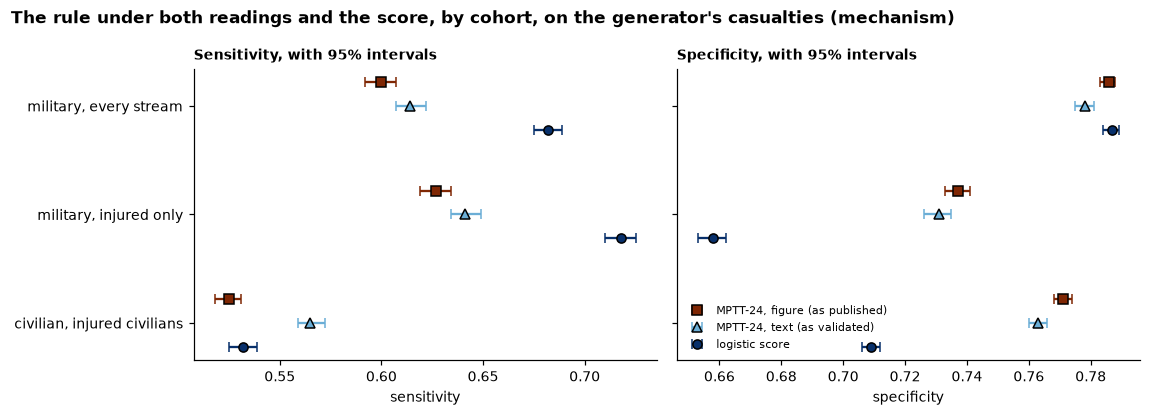

In [8]:
view = table[table["scan"] == "scan before hospital"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
cohorts = list(dict.fromkeys(view["cohort"]))
methods = list(dict.fromkeys(view["method"]))
styles = {methods[0]: (DARK, "s"), methods[1]: (PALE, "^"), methods[2]: (MID, "o")}
for ax, measure in zip(axes, ("sensitivity", "specificity")):
    for j, method in enumerate(methods):
        rows = view[view["method"] == method]
        y = np.arange(len(cohorts)) + (j - 1) * 0.22
        lo = rows[f"{measure} 95% interval"].str.split(" to ").str[0].astype(float)
        hi = rows[f"{measure} 95% interval"].str.split(" to ").str[1].astype(float)
        colour, marker = styles[method]
        ax.errorbar(rows[measure], y, xerr=[rows[measure] - lo, hi - rows[measure]], fmt=marker, color=colour,
                    markeredgecolor="black", capsize=3, label=method)
    ax.set_yticks(range(len(cohorts)), cohorts)
    ax.set_xlabel(measure)
    ax.set_title(f"{measure.capitalize()}, with 95% intervals", loc="left", fontsize=9)
axes[0].invert_yaxis()
axes[1].legend(fontsize=7, frameon=False, loc="lower left")
fig.suptitle("The rule under both readings and the score, by cohort, on the generator's casualties (mechanism)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### The curve beside the published points

The score's curve on the generator, with the MPTT-24's own points on the generator and the published points of the MPTT-24 (E-09) and the earlier MPTT (E-03, E-05, E-07). The published points belong to their cohorts and to hospital observations (E-11); the curve belongs to the generator. They share an axis, not a population. Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).

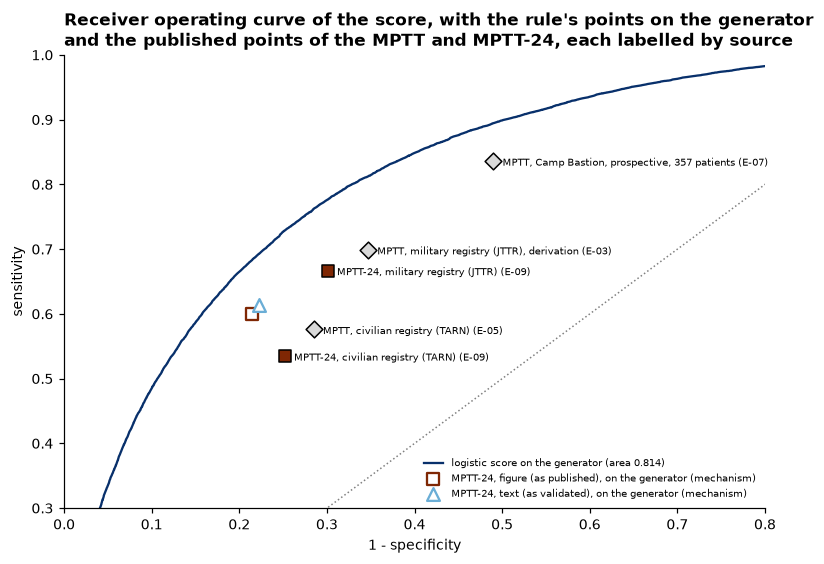

In [9]:
fig, ax = plt.subplots(figsize=(7.4, 5.2))
ax.plot(r["fpr"], r["tpr"], color=MID, linewidth=1.5, label=f"logistic score on the generator (area {r['auc']:.3f})")
for name, (colour, marker) in styles.items():
    if name == methods[2]:
        continue
    pt = r["points"][name]
    ax.scatter(1 - pt["specificity"][0], pt["sensitivity"][0], s=70, marker=marker, facecolor="white",
               edgecolor=colour, linewidth=1.5, zorder=4, label=f"{name}, on the generator (mechanism)")
for x in freq.PUBLISHED:
    marker = "D" if x.rule == "MPTT" else "s"
    ax.scatter(1 - x.specificity, x.sensitivity, s=60, marker=marker, color=DARK if x.rule == "MPTT-24" else LIGHT,
               edgecolor="black", zorder=3)
    ax.annotate(f"{x.rule}, {x.cohort} ({x.source})", (1 - x.specificity, x.sensitivity), fontsize=6.5,
                xytext=(6, -3), textcoords="offset points")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
ax.set_xlim(0, 0.8)
ax.set_ylim(0.3, 1.0)
ax.set_xlabel("1 - specificity")
ax.set_ylabel("sensitivity")
ax.legend(fontsize=6.5, frameon=False, loc="lower right")
ax.set_title("Receiver operating curve of the score, with the rule's points on the generator\nand the published "
             "points of the MPTT and MPTT-24, each labelled by source", loc="left")
plt.tight_layout()
plt.show()

### Protocol against practice, and one scan in two rooms

In ten Dutch hospitals, 4,950 patients, the triage protocol applied on its own would have given an under-triage of 63.8% and an over-triage of 7.4%; in practice they were 21.6% and 30.6% (E-88). These are under-triage and over-triage as that study reports them. They are not sensitivity and specificity, and over-triage is not 1 minus specificity: the MPTT-24's authors define it as 1 minus the positive predictive value (E-12).

The same eFAST scan for free fluid was 74% sensitive and 98% specific in pooled in-hospital studies (E-14), and 25% and 96% in one civilian helicopter service before hospital (E-16). One test, two rooms, two operating points.

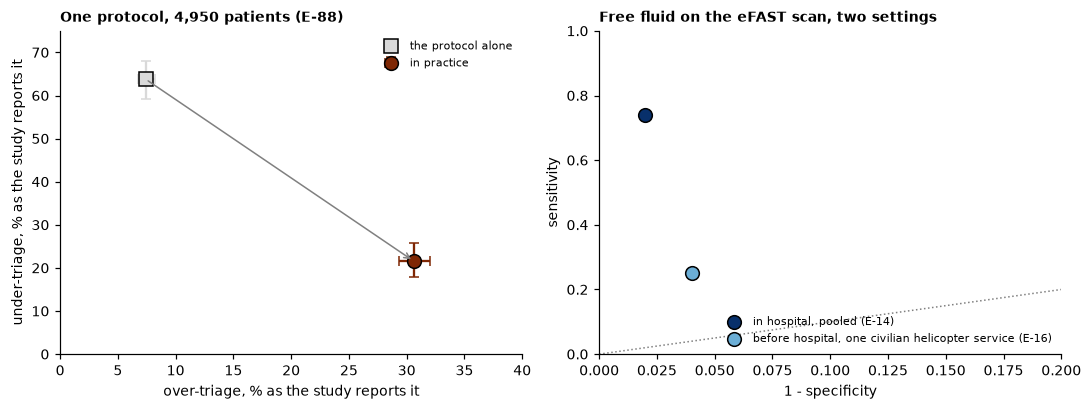

In [10]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8))
for name, colour, marker in (("the protocol alone", LIGHT, "s"), ("in practice", DARK, "o")):
    v = freq.PROTOCOL_PRACTICE[name]
    ax.errorbar(v["over"][0], v["under"][0], xerr=[[v["over"][0] - v["over"][1]], [v["over"][2] - v["over"][0]]],
                yerr=[[v["under"][0] - v["under"][1]], [v["under"][2] - v["under"][0]]], fmt=marker, color=colour,
                markeredgecolor="black", markersize=9, capsize=3, label=name)
ax.annotate("", xy=(30.6, 21.6), xytext=(7.4, 63.8), arrowprops={"arrowstyle": "->", "color": "grey"})
ax.set_xlim(0, 40)
ax.set_ylim(0, 75)
ax.set_xlabel("over-triage, % as the study reports it")
ax.set_ylabel("under-triage, % as the study reports it")
ax.legend(fontsize=7, frameon=False)
ax.set_title("One protocol, 4,950 patients (E-88)", loc="left", fontsize=9)
for (name, (sens, spec)), colour in zip(freq.SCAN_SETTINGS.items(), (MID, PALE)):
    bx.scatter(1 - spec, sens, s=80, color=colour, edgecolor="black", zorder=3, label=name)
bx.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
bx.set_xlim(0, 0.2)
bx.set_ylim(0, 1)
bx.set_xlabel("1 - specificity")
bx.set_ylabel("sensitivity")
bx.legend(fontsize=7, frameon=False, loc="lower right")
bx.set_title("Free fluid on the eFAST scan, two settings", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

### One cohort is one sample

The prospective MPTT cohort in E-07 had 357 patients. How far can one estimate from that many sit from the long-run value? The generator can show this for its own casualties: draw 357 injured casualties again and again, estimate the MPTT-24's sensitivity each time, and look at the spread.

This illustrates sample size on synthetic data. It does not explain E-07's figure, which came from a different rule, a different cohort and real patients.

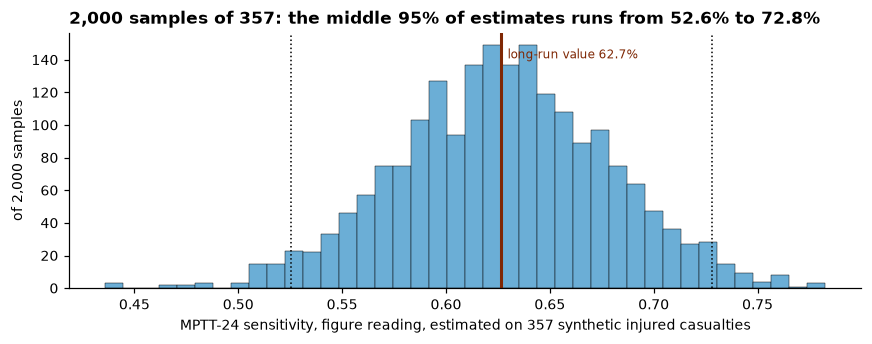

casualties in need in a sample of 357: from 65 to 129


In [11]:
rs = freq.resampled_sensitivity()
lo, hi = rs["middle 95%"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(rs["estimates"], bins=40, color=PALE, edgecolor="black", linewidth=0.3)
ax.axvline(rs["long run"], color=DARK, linewidth=2)
ax.text(rs["long run"] + 0.003, ax.get_ylim()[1] * 0.9, f"long-run value {rs['long run']:.1%}", fontsize=8, color=DARK)
for x in (lo, hi):
    ax.axvline(x, color="black", linestyle=":", linewidth=1)
ax.set_xlabel(f"MPTT-24 sensitivity, figure reading, estimated on {freq.BASTION_N} synthetic injured casualties")
ax.set_ylabel(f"of {freq.RESAMPLES:,} samples")
ax.set_title(f"{freq.RESAMPLES:,} samples of {freq.BASTION_N}: the middle 95% of estimates runs from {lo:.1%} to {hi:.1%}",
             loc="left")
plt.tight_layout()
plt.show()
print(f"casualties in need in a sample of {freq.BASTION_N}: from {rs['in need'].min()} to {rs['in need'].max()}")

## Treatment: reading a trial

This section is about treatment decisions, and its results are kept apart from the diagnosis results above.

**The answer to the hook.** PROPPR's 24-hour mortality was 12.7% against 17.0%, a difference of 4.2 points, with a 95% interval from 9.6 points fewer deaths to 1.1 points more, P=.12 (E-72). "No significant difference" is a statement about the trial: with 680 patients, an interval that wide includes no effect. It does not say the ratio does not matter. The same interval allows a benefit of nearly ten points. Lens 03 returns to this trial and asks the question a clinician wants answered (E-73).

Beside it, CRASH-2 randomised 20,211 patients to tranexamic acid or placebo (E-19). Death from any cause was 14.5% against 16.0%, a relative risk of 0.91 (0.85 to 0.97) (E-20), and death from bleeding 4.9% against 5.7%, 0.85 (0.76 to 0.96) (E-21). A small effect, shown clearly by a very large trial. CRASH-2 is civilian, so applying its figures to a military casualty is an assumption.

RePHILL randomised 432 patients in four English prehospital critical care services to red cells with lyophilised plasma, or to saline (E-77). Its composite of death or failure to clear lactate was 128 of 199 against 136 of 210, 64.3% against 64.8%, and the trial's adjusted interval runs from 9.0 points fewer to 9.0 points more. Death within 3 hours was 16% against 22%, a relative risk of 0.75 (0.50 to 1.13).

Where the register holds the counts, the interval can be recomputed by hand. It does for CRASH-2, with the analysed denominators from E-19, and for RePHILL's composite. It does not for PROPPR, whose interval is quoted.

In [12]:
import math
k1, n1, k0, n0 = 489, 10_060, 574, 10_067        # CRASH-2 deaths from bleeding (E-21), analysed (E-19)
rr = (k1 / n1) / (k0 / n0)
se = math.sqrt(1 / k1 - 1 / n1 + 1 / k0 - 1 / n0)  # standard error of the log relative risk
by_hand = (rr, rr * math.exp(-1.96 * se), rr * math.exp(1.96 * se))
library = freq.trials()[2].relative_risk
print(f"by hand:  relative risk {by_hand[0]:.3f} ({by_hand[1]:.3f} to {by_hand[2]:.3f})")
print(f"library:  relative risk {library[0]:.3f} ({library[1]:.3f} to {library[2]:.3f})")
pd.DataFrame([{"trial": t.trial, "outcome": t.outcome, "treated": f"{t.treated_pct:.1f}%",
               "control": f"{t.control_pct:.1f}%",
               "difference, points": "" if t.difference is None else freq.difference_words(t.difference),
               "relative risk": "" if t.relative_risk is None else
               f"{t.relative_risk[0]:.2f} ({t.relative_risk[1]:.2f} to {t.relative_risk[2]:.2f})",
               "how": "recomputed" if t.recomputed else "quoted", "source": t.source} for t in freq.trials()])

by hand:  relative risk 0.853 (0.758 to 0.959)
library:  relative risk 0.853 (0.758 to 0.959)


,trial,outcome,treated,control,"difference, points",relative risk,how,source
0,PROPPR,death within 24 hours,12.7%,17.0%,4.2 fewer deaths in every 100 with the treatment (from 9.6 fewer to 1.1 more),,quoted,E-72
1,CRASH-2,death from any cause,14.5%,16.0%,1.5 fewer deaths in every 100 with the treatment (from 2.5 fewer to 0.5 fewer),0.91 (0.85 to 0.97),recomputed,"E-19, E-20"
2,CRASH-2,death from bleeding,4.9%,5.7%,0.8 fewer deaths in every 100 with the treatment (from 1.5 fewer to 0.2 fewer),0.85 (0.76 to 0.96),recomputed,"E-19, E-21"
3,RePHILL,death or failure to clear lactate,64.3%,64.8%,0.4 fewer deaths in every 100 with the treatment (from 9.7 fewer to 8.8 more),,recomputed,E-77
4,RePHILL,death within 3 hours,16.0%,22.0%,,0.75 (0.50 to 1.13),quoted,E-77


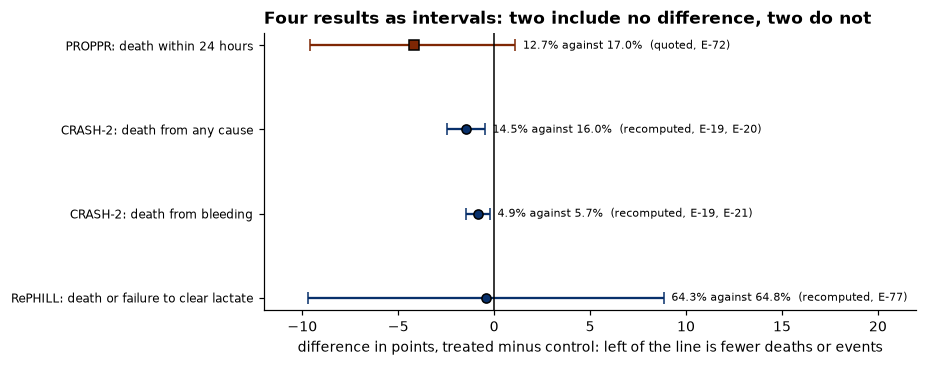

In [13]:
shown = [t for t in freq.trials() if t.difference is not None]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for i, t in enumerate(shown):
    d, lo, hi = t.difference
    colour = MID if t.recomputed else DARK
    ax.errorbar(d, i, xerr=[[d - lo], [hi - d]], fmt="o" if t.recomputed else "s", color=colour,
                markeredgecolor="black", capsize=4)
    ax.text(hi + 0.4, i, f"{t.treated_pct:.1f}% against {t.control_pct:.1f}%  ({'recomputed' if t.recomputed else 'quoted'}, {t.source})",
            va="center", fontsize=7)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(range(len(shown)), [f"{t.trial}: {t.outcome}" for t in shown], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(-12, 22)
ax.set_xlabel("difference in points, treated minus control: left of the line is fewer deaths or events")
ax.set_title("Four results as intervals: two include no difference, two do not", loc="left")
plt.tight_layout()
plt.show()

### Where the line is drawn

The 0.05 line is a convention, and trials can set it otherwise. A prehospital trial of tranexamic acid in brain injury set its thresholds at 0.1 for benefit and 0.025 for harm (E-79): easier to declare a benefit than a harm, by design.

CRASH-2 also set a rule for its subgroups before it began. Its effect on death from any cause by time from injury was 0.87 within an hour, 0.87 at one to three hours and 1.00 after three hours, and the test for heterogeneity gave p = 0.11 against a prespecified threshold of p < 0.001 (E-20). By the trial's own rule, the subgroups did not show that timing mattered. The timing result came later, from an exploratory analysis of death from bleeding (E-22, E-23). That analysis was then checked against rival explanations: restricting to blunt trauma, to casualties without head injury, or to a systolic pressure below 100 did not remove it, and the interaction with time stayed at p < 0.0001 (E-124). The order matters: a subgroup found by looking is a question, and what makes it more believable is shown, not asserted.

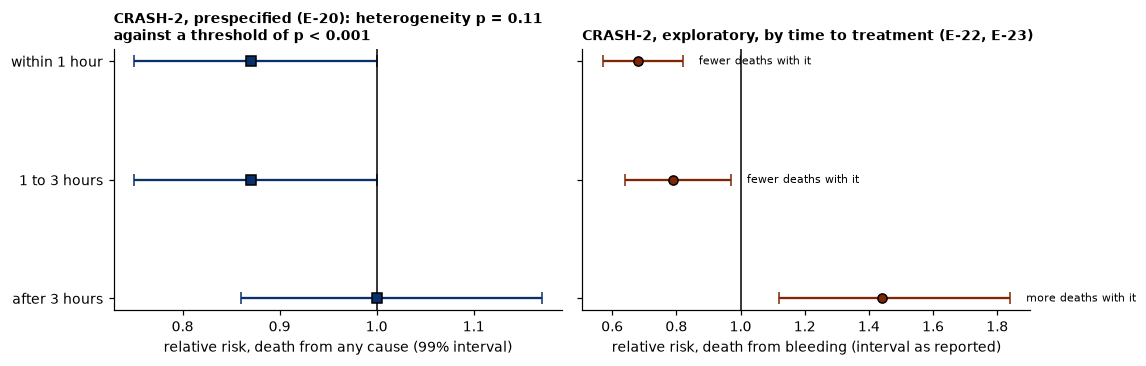

In [14]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
for i, (band, (rr_, lo_, hi_)) in enumerate(freq.CRASH2_TIME_SUBGROUPS):
    ax.errorbar(rr_, i, xerr=[[rr_ - lo_], [hi_ - rr_]], fmt="s", color=MID, markeredgecolor="black", capsize=4)
ax.set_yticks(range(3), [b for b, _ in freq.CRASH2_TIME_SUBGROUPS])
ax.axvline(1, color="black", linewidth=1)
ax.set_xlabel("relative risk, death from any cause (99% interval)")
ax.set_title(f"CRASH-2, prespecified (E-20): heterogeneity p = {freq.CRASH2_HETEROGENEITY_P}\nagainst a threshold "
             f"of p < {freq.CRASH2_PRESPECIFIED_THRESHOLD}", loc="left", fontsize=9)
for i, b in enumerate(rules.E22_BANDS):
    rr_, lo_, hi_ = b["rr"]
    bx.errorbar(rr_, i, xerr=[[rr_ - lo_], [hi_ - rr_]], fmt="o", color=DARK, markeredgecolor="black", capsize=4)
    words = "fewer deaths with it" if hi_ < 1 else "more deaths with it"
    bx.text(hi_ + 0.05, i, words, va="center", fontsize=7)
bx.axvline(1, color="black", linewidth=1)
bx.set_xlabel("relative risk, death from bleeding (interval as reported)")
bx.set_title("CRASH-2, exploratory, by time to treatment (E-22, E-23)", loc="left", fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## The failure: one number in the wrong room, and absence read as evidence

Two failures, both common.

**One accuracy figure quoted for the wrong setting.** Quote the in-hospital 74% for a scan done before hospital, where the one study found 25% (E-14, E-16), and a reader expects about 74 of every 100 with free fluid to be found, where the pre-hospital figure says about 25. Quote the MPTT-24's sensitivity from the military registry, 66.7%, for the civilian registry, where it was 53.5% (E-09), and about 13 of every 100 in need are expected to be flagged who would not be. Each number is right for its room.

**A non-significant result read as no effect.** PROPPR's interval runs from 9.6 points fewer deaths to 1.1 points more (E-72); RePHILL's composite from 9.0 fewer to 9.0 more (E-77). "No significant difference" in either is compatible with a benefit of several points. Read as "no effect", it throws that away.

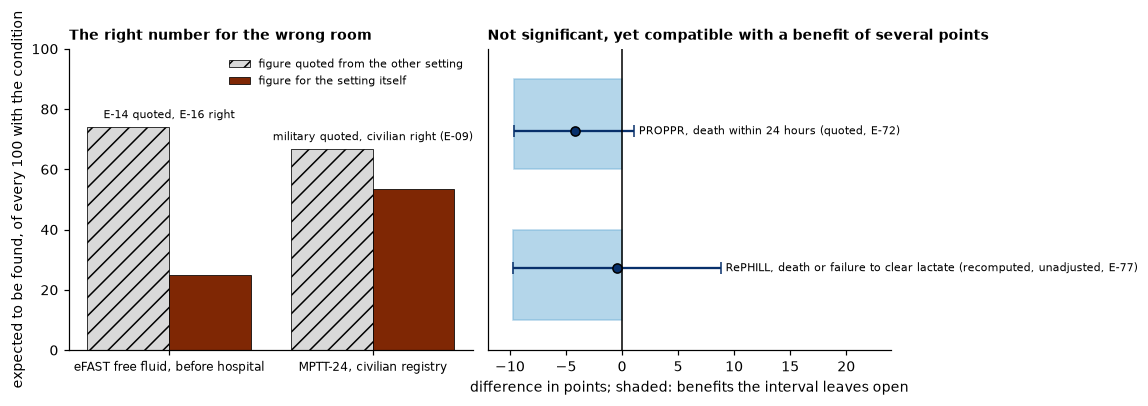

In [15]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.6))
cases = (("eFAST free fluid, before hospital", 0.74, 0.25, "E-14 quoted, E-16 right"),
         ("MPTT-24, civilian registry", 0.667, 0.535, "military quoted, civilian right (E-09)"))
x = np.arange(len(cases))
ax.bar(x - 0.2, [c[1] * 100 for c in cases], 0.4, color=LIGHT, edgecolor="black", hatch="//", linewidth=0.5,
       label="figure quoted from the other setting")
ax.bar(x + 0.2, [c[2] * 100 for c in cases], 0.4, color=DARK, edgecolor="black", linewidth=0.5,
       label="figure for the setting itself")
for xi, c in zip(x, cases):
    ax.text(xi, max(c[1], c[2]) * 100 + 3, c[3], ha="center", fontsize=7)
ax.set_xticks(x, [c[0] for c in cases], fontsize=8)
ax.set_ylim(0, 100)
ax.set_ylabel("expected to be found, of every 100 with the condition")
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_title("The right number for the wrong room", loc="left", fontsize=9)
for i, t in enumerate((freq.trials()[0], freq.trials()[3])):
    d, lo, hi = t.difference
    bx.axvspan(lo, min(hi, 0), ymin=(1 - i) / 2 + 0.1, ymax=(1 - i) / 2 + 0.4, color=PALE, alpha=0.5)
    bx.errorbar(d, 1 - i, xerr=[[d - lo], [hi - d]], fmt="o", color=MID, markeredgecolor="black", capsize=4)
    how = "recomputed, unadjusted" if t.recomputed else "quoted"
    bx.text(hi + 0.4, 1 - i, f"{t.trial}, {t.outcome} ({how}, {t.source})", va="center", fontsize=7)
bx.axvline(0, color="black", linewidth=1)
bx.set_yticks([])
bx.set_ylim(-0.6, 1.6)
bx.set_xlim(-12, 24)
bx.set_xlabel("difference in points; shaded: benefits the interval leaves open")
bx.set_title("Not significant, yet compatible with a benefit of several points", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label: synthetic data can only confirm the model that made them. Axes 3, 4 and 5 are stated. Axis 7, the value of the decision, waits for the decision theory lens.

The diagnosis column scores the logistic score at its threshold against need for a life-saving intervention, on all 100,000 synthetic casualties of the military cohort. The baseline is the MPTT-24 read as its figure was published, with the text reading beside it, labelled as validated (D-24). Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The treatment column is a trial read as an estimate and an interval; its computed row runs on the CRASH-2 fixture, 200 synthetic rows, because real trial data are not read here. Fit is native for diagnosis: sorting casualties by error rates is what this lens does. It is weak for treatment: the lens reads trials; it does not choose a treatment for one casualty.

In [16]:
freq.seven_axes()

,diagnosis: logistic score,"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)",treatment: trial reading
axis,,,,
1 Discrimination (mechanism),"sensitivity 68.2% (67.5% to 68.9%), specificity 78.7% (78.4% to 78.9%); area under the curve 0.814; 100,000 synthetic casualties","sensitivity 60.0%, specificity 78.6%","sensitivity 61.4%, specificity 77.8%","Not a classifier. On the CRASH-2 fixture, 17 of 92 died with tranexamic acid and 22 of 108 with placebo: 1.9 fewer deaths in every 100 with the treatment (f..."
2 Calibration (mechanism),Brier 0.110; mean probability minus share in need +0.001,"Brier 0.245; it flags 11.2 points more than are in need. A rule gives no probability, so the Brier score is the share misclassified",Brier 0.249; it flags 12.1 points more than are in need,Not applicable
3 Uncertainty expressed,An interval on every rate: where the estimate would fall in repeated samples,None: a priority,None: a priority,An interval on the difference
4 What it needed,"Labelled cases: 100,000 synthetic casualties to fit seven weights (mechanism)",Rules only at the point of use (E-08),Rules only at the point of use (E-08),A randomised trial: deaths counted in each arm
5 Readability,A weighted sum of four signs: a medic needs the weights or a device; the decision is one comparison,"Six yes-or-no steps, one observation each","Six yes-or-no steps, one observation each","Two percentages, their difference and its interval"
"6 Robustness, setting and cohort changed (mechanism)","Scan in hospital: sensitivity 68.2%, specificity 78.7%, unchanged because the setting changes only the scan. Civilian cohort: sensitivity 53.2%, specificity...","Civilian cohort: sensitivity 52.5%, specificity 77.1%","Civilian cohort: sensitivity 56.5%, specificity 76.3%",Not applicable: the setting does not enter
7 Decision value,Pending until lens 10,Pending until lens 10,Pending until lens 10,Pending until lens 10


In [17]:
card = pd.DataFrame([vars(row) for row in freq.LENS.scorecard()])
card["baseline"] = card["baseline"].astype(object).where(card["baseline"].notna(),
                                                         "not applicable: the rule gives no treatment effect")
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, logistic score at its threshold against need for a life-saving intervention, scan before hospital",6.820e-01,0.6,mechanism,native,generator
1,diagnosis,"specificity, logistic score at its threshold against need for a life-saving intervention, scan before hospital",7.866e-01,0.786,mechanism,native,generator
2,diagnosis,"Brier score, logistic score at its threshold against need for a life-saving intervention, scan before hospital",1.096e-01,0.245,mechanism,native,generator
3,diagnosis,"mean probability minus share in need, logistic score at its threshold against need for a life-saving intervention, scan before hospital",7.000e-04,0.112,mechanism,native,generator
4,diagnosis,"sensitivity, logistic score at its threshold against need for a life-saving intervention, scan in hospital",6.820e-01,0.6,mechanism,native,generator
5,diagnosis,"specificity, logistic score at its threshold against need for a life-saving intervention, scan in hospital",7.866e-01,0.786,mechanism,native,generator
6,diagnosis,"Brier score, logistic score at its threshold against need for a life-saving intervention, scan in hospital",1.096e-01,0.245,mechanism,native,generator
7,diagnosis,"mean probability minus share in need, logistic score at its threshold against need for a life-saving intervention, scan in hospital",7.000e-04,0.112,mechanism,native,generator
8,treatment,"difference in death, tranexamic acid minus placebo, points, CRASH-2 fixture (synthetic rows)",-1.890e+00,not applicable: the rule gives no treatment effect,mechanism,weak,fixture:crash2.csv


Two rows carry the lesson. At the same specificity the score finds more of those in need than the rule, because it keeps the whole value of each sign where the rule keeps only which side of a threshold it falls. And its calibration row is close to zero: a probability can be checked against the share that comes true, where a priority cannot. The treatment row is a reminder that the estimate comes with an interval, and on 200 rows the interval is wide.

**Teach back.** In one sentence, why is "no significant difference" not the same as "no difference"?

## The brain analogy, and where it breaks

**What it resembles.** Signal detection is also a model of perception: a listener hears a faint tone in noise and must say whether it was there. The listener's sensitivity and where they set their criterion are separate things, and the theory measures both. A medic deciding whether a casualty is urgent is in the same position: some urgent casualties look well, some well ones look urgent, and the line is set by judging which mistake is worse.

**Where it breaks.** Signal detection models a decision criterion. It says nothing about how the brain sets one, or why practice moves the line when a protocol does not. And the frequentist frame describes what happens under repetition; it gives no way, on its own terms, to combine six trials of six populations into one belief. That is the handover to the Bayesian lens.